Training Data Shape: (27455, 784)
Testing Data Shape: (7172, 784)
Number of Classes: 24


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,296 (430.84 KB)

 Trainable params: 110,296 (430.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.3304 - loss: 2.1840 - val_accuracy: 0.5178 - val_loss: 1.4961
Epoch 2/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6016 - loss: 1.2407 - val_accuracy: 0.6617 - val_loss: 1.0161
Epoch 3/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6970 - loss: 0.9287 - val_accuracy: 0.7298 - val_loss: 0.8242
Epoch 4/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7657 - loss: 0.7219 - val_accuracy: 0.7859 - val_loss: 0.6281
Epoch 5/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8243 - loss: 0.5533 - val_accuracy: 0.8420 - val_loss: 0.4772
Epoch 6/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8667 - loss: 0.4288 - val_accuracy: 0.8893 - val_loss: 0.3639
Epoch 7/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9005 - loss: 0.3256 - val_accuracy: 0.9173 - val_loss: 0.2838
Epoch 8/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9205 - loss: 0.2590 - val_accuracy: 0.

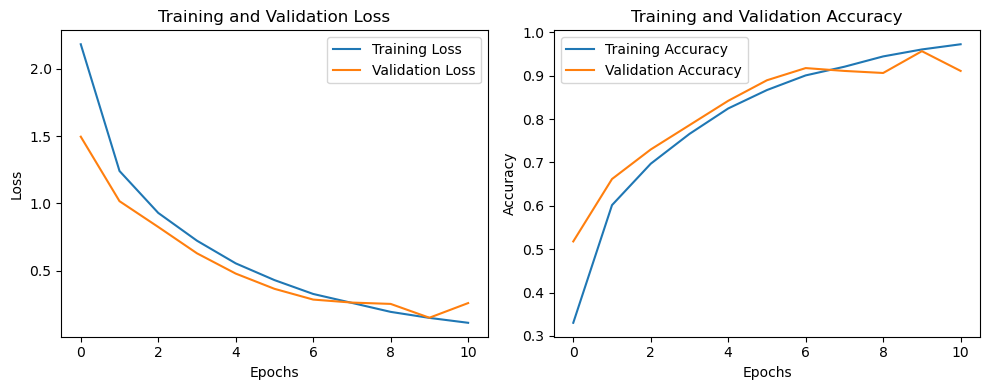

In [1]:
# Step 1: Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# Step 2: Load training and testing data
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Separate features and labels
x_train = train.iloc[:, 1:].values
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Convert original labels into continuous class indices
classes = np.sort(np.unique(y_train))

y_train = np.searchsorted(classes, y_train)
y_test = np.searchsorted(classes, y_test)

# Display dataset information
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)
print("Number of Classes:", len(classes))

# Step 3: Define FNN architecture
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(24, activation="softmax")
])

# Compile model using Adam optimizer
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

# Step 4: Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

# Step 5: Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

# Step 6: Plot training loss and accuracy
plt.figure(figsize=(10, 4))

# Loss Graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

# Accuracy Graph
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,296 (430.84 KB)

 Trainable params: 110,296 (430.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9966 - loss: 0.0487 - val_accuracy: 0.9982 - val_loss: 0.0472
Epoch 2/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9979 - loss: 0.0431 - val_accuracy: 0.9687 - val_loss: 0.1015
Epoch 3/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9985 - loss: 0.0393 - val_accuracy: 0.9414 - val_loss: 0.1587
Epoch 4/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9984 - loss: 0.0365 - val_accuracy: 0.9985 - val_loss: 0.0351
Epoch 5/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9992 - loss: 0.0332 - val_accuracy: 1.0000 - val_loss: 0.0293
Epoch 6/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9994 - loss: 0.0302 - val_accuracy: 0.9996 - val_loss: 0.0300
Epoch 7/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9995 - loss: 0.0282 - val_accuracy: 0.9993 - val_loss: 0.0271
Epoch 8/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9994 - loss: 0.0263 - val_accuracy: 1.

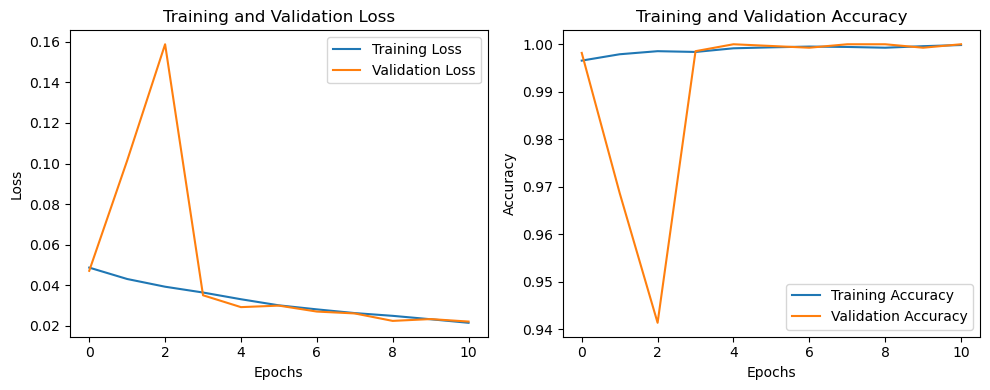

In [3]:
from tensorflow.keras.optimizers import SGD
# Compile model using Adam optimizer
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

# Step 4: Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

# Step 5: Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

# Step 6: Plot training loss and accuracy
plt.figure(figsize=(10, 4))

# Loss Graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

# Accuracy Graph
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()